# Task Decomposition with LangGraph: Sequential and Parallel Execution

## Tutorial Overview

In this tutorial, you'll learn how to build an intelligent task decomposition system using **LangGraph**. The system will:

- Analyze complex queries and break them into sub-queries
- Determine whether sub-queries should execute sequentially or in parallel
- Execute searches using the Tavily API
- Synthesize results into comprehensive answers

## Learning Objectives

By the end of this tutorial, you will be able to:

1. Understand when to use **sequential** vs **parallel** task execution
2. Build a LangGraph workflow with a **planning node** (query analyzer)
3. Implement **sequential execution** where one query depends on previous results
4. Implement **parallel execution** using `asyncio.gather` for independent queries
5. Use the **Tavily search tool** for web searches
6. Synthesize results from multiple queries into coherent answers

## Execution Strategies Explained

### Sequential Execution
Used when sub-queries **depend on previous results**:

**Example:** "AI products launched by the company that acquired DeepMind in 2024"

**Flow:**
1. Query 1: "Which company acquired DeepMind?" → Result: "Google"
2. Use result from Query 1 in Query 2: "AI products launched by Google in 2024"
3. Return final results

Must execute queries **one after another** because Query 2 needs Query 1's answer.

### Parallel Execution
Used when sub-queries are **independent**:

**Example:** "Summarize Tesla's Q4 2024 earnings, recent product launches, and leadership changes"

**Flow:**
1. Query 1: "Tesla Q4 2024 earnings" 
2. Query 2: "Tesla recent product launches" 
3. Query 3: "Tesla leadership changes"
4. All queries execute **simultaneously** using `asyncio.gather`
5. Aggregate results

**Benefits:** Faster completion (parallel I/O), no dependencies between queries.

## Visual Workflow

```
START
  ↓
Query Analyzer (Planning)
  ↓
[Conditional Edge]
  ↓
  ├─→ Sequential Execution → Query 1 → Synthesize → Query 2 → Search Results
  │                                                                ↓
  └─→ Parallel Execution → [Query 1, Query 2, Query 3] → Search Results
                                                                   ↓
                                                            Final Synthesis
                                                                   ↓
                                                                  END
```

## Prerequisites

- Basic Python knowledge
- Understanding of async/await in Python
- API keys for:
  - OpenAI (or another LLM provider)
  - Tavily (for web search)

## Part 1: Environment Setup

First, let's install the required packages and load our environment variables.

**Required packages:**
- `langgraph` - For building the workflow graph
- `langchain-openai` - For LLM integration
- `langchain-tavily` - For web search
- `python-dotenv` - For loading API keys
- `nest-asyncio` - To enable asyncio in Jupyter notebooks

In [16]:
# Install required packages
# Uncomment the following line if you need to install the packages
# !pip install -qU langgraph langchain-openai langchain-tavily python-dotenv nest-asyncio

In [17]:
# Load environment variables
from dotenv import load_dotenv
import os

# Load API keys from .env file
load_dotenv()

# Verify that keys are loaded
assert os.getenv("OPENAI_API_KEY"), "OPENAI_API_KEY not found in environment"
assert os.getenv("TAVILY_API_KEY"), "TAVILY_API_KEY not found in environment"

print("Environment variables loaded successfully!")

Environment variables loaded successfully!


## Part 2: Import Dependencies

Let's import all the libraries we'll need:
- **LangGraph** for workflow orchestration
- **LangChain** for LLM and search tool integration
- **asyncio** for parallel execution
- **Pydantic** for structured outputs

In [18]:
from typing import TypedDict, List, Literal
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_tavily import TavilySearch
from pydantic import BaseModel, Field
import asyncio
import nest_asyncio
import json

# Apply nest_asyncio to allow asyncio.run() in Jupyter notebooks
nest_asyncio.apply()

print("All imports successful!")
print("nest_asyncio applied - asyncio.run() will now work in Jupyter!")

All imports successful!
nest_asyncio applied - asyncio.run() will now work in Jupyter!


## Part 3: Define the Workflow State

In LangGraph, **state** represents the data flowing through your workflow. Each node reads from and updates this state.

Our workflow state will track:
- **query**: The original user query
- **sub_queries**: List of decomposed sub-queries
- **execution_strategy**: Either "sequential" or "parallel"
- **search_results**: Results from Tavily searches
- **synthesis**: Intermediate synthesis (used in sequential execution)
- **final_answer**: The final comprehensive answer

In [19]:
class WorkflowState(TypedDict):
    """State schema for task decomposition workflow."""
    
    # Original user query
    query: str
    
    # Decomposed sub-queries
    sub_queries: List[str]
    
    # Execution strategy: 'sequential' or 'parallel'
    execution_strategy: str
    
    # Number of sequential steps (for sequential execution)
    num_sequential_steps: int
    
    # Search results from Tavily
    search_results: List[str]
    
    # Intermediate synthesis (for sequential execution)
    synthesis: str
    
    # Final answer to return to user
    final_answer: str

print("State schema defined!")
print("\nState fields:")
for field, field_type in WorkflowState.__annotations__.items():
    print(f"  - {field}: {field_type}")

State schema defined!

State fields:
  - query: <class 'str'>
  - sub_queries: typing.List[str]
  - execution_strategy: <class 'str'>
  - num_sequential_steps: <class 'int'>
  - search_results: typing.List[str]
  - synthesis: <class 'str'>
  - final_answer: <class 'str'>


## Part 4: Initialize LLM and Search Tool

Let's set up:
1. **ChatOpenAI** - Our LLM for analysis and synthesis
2. **Query Analysis Schema** - Pydantic model for structured output from the query analyzer
3. **TavilySearch** - Web search tool

In [20]:
# Define Pydantic model for query analysis
class QueryAnalysis(BaseModel):
    """Schema for query analysis results."""
    
    execution_strategy: Literal["sequential", "parallel"] = Field(
        description="Execution strategy: 'sequential' if sub-queries depend on each other, 'parallel' if they are independent"
    )
    sub_queries: List[str] = Field(
        description="List of sub-queries to execute. For sequential: provide only the FIRST query (additional queries will be generated dynamically). For parallel: 2-4 independent queries."
    )
    num_sequential_steps: int = Field(
        default=2,
        description="For sequential execution only: Total number of sequential steps needed (2-4). Ignored for parallel execution."
    )
    reasoning: str = Field(
        description="Brief explanation of why this strategy was chosen"
    )

# Initialize the language model
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

# Create structured output model for query analysis
query_analyzer = llm.with_structured_output(QueryAnalysis)

# Initialize Tavily search tool
tavily_search = TavilySearch(
    max_results=5,
    topic="general",
    search_depth="basic"
)

print("LLM, query analyzer, and Tavily search tool initialized!")
print("\nQuery Analysis Schema:")
print(f"  - execution_strategy: Literal['sequential', 'parallel']")
print(f"  - sub_queries: List[str]")
print(f"  - num_sequential_steps: int (for sequential only)")
print(f"  - reasoning: str")

LLM, query analyzer, and Tavily search tool initialized!

Query Analysis Schema:
  - execution_strategy: Literal['sequential', 'parallel']
  - sub_queries: List[str]
  - num_sequential_steps: int (for sequential only)
  - reasoning: str


## Part 5: Build the Query Analyzer Node

The **Query Analyzer** is the planning node that:
1. Analyzes the user's query
2. Determines if sub-queries should run sequentially or in parallel
3. Generates appropriate sub-queries

This is the "brain" of our workflow that decides the execution strategy.

In [21]:
def query_analyzer_node(state: WorkflowState) -> WorkflowState:
    """
    Analyzes the user query and determines execution strategy.
    
    Returns:
        Updated state with 'execution_strategy', 'sub_queries', and 'num_sequential_steps' populated
    """
    query = state["query"]
    
    print(f"\n{'='*80}")
    print("QUERY ANALYZER NODE")
    print(f"{'='*80}")
    print(f"Analyzing query: {query}")
    
    # Create prompt for query analysis
    system_prompt = """You are a query decomposition expert. Analyze the user's query and determine the best execution strategy.

**SEQUENTIAL Execution:**
Use when sub-queries DEPEND on previous results (multi-hop reasoning).

Examples:
1. "AI products launched by the company that acquired DeepMind in 2024" (2 steps)
   - Step 1: "Which company acquired DeepMind?" → Get answer
   - Step 2: Generate query based on answer: "AI products launched by [Company] in 2024"

2. "What products has the CEO of the company that makes iPhone announced in 2024?" (3 steps)
   - Step 1: "Which company makes iPhone?" → Get answer  
   - Step 2: Generate query: "Who is the CEO of [Company]?" → Get answer
   - Step 3: Generate query: "Products announced by [CEO] in 2024"

For sequential: 
- Provide ONLY the first query
- Specify how many sequential steps are needed (2-4)
- Subsequent queries will be generated dynamically based on previous results

**PARALLEL Execution:**
Use when sub-queries are INDEPENDENT.

Example: "Summarize Tesla's Q4 2024 earnings, recent product launches, and leadership changes"
  - Query 1: "Tesla Q4 2024 earnings"
  - Query 2: "Tesla recent product launches"  
  - Query 3: "Tesla leadership changes"
  
For parallel: Provide ALL sub-queries (2-4 queries) that can run simultaneously.

Provide your analysis with clear reasoning."""
    
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": f"Query: {query}"}
    ]
    
    # Use structured output to get query analysis
    result = query_analyzer.invoke(messages)
    
    print(f"\nExecution Strategy: {result.execution_strategy.upper()}")
    if result.execution_strategy == "sequential":
        print(f"Number of Sequential Steps: {result.num_sequential_steps}")
    print(f"Reasoning: {result.reasoning}")
    print(f"\nSub-queries generated:")
    for i, sq in enumerate(result.sub_queries, 1):
        print(f"  {i}. {sq}")
    
    return {
        **state,
        "execution_strategy": result.execution_strategy,
        "sub_queries": result.sub_queries,
        "num_sequential_steps": result.num_sequential_steps
    }

print("Query analyzer node created!")

Query analyzer node created!


## Part 6: Build the Sequential Execution Node

The **Sequential Execution Node** handles queries where results depend on each other through **multi-hop reasoning**.

The node uses a **loop** to handle any number of sequential steps (2-4):

1. Execute the first sub-query with Tavily
2. Synthesize results with the LLM
3. **Loop** for remaining steps:
   - Generate the next sub-query based on current synthesis and original query
   - Execute the query with Tavily
   - Update the synthesis with new information
4. Return all results

This approach can handle complex multi-hop queries like:
- 2-hop: "Products by the company that acquired X"
- 3-hop: "Products by the CEO of the company that makes X"
- 4-hop: "Initiatives by the person who replaced the CEO of company X"

In [22]:
def sequential_execution_node(state: WorkflowState) -> WorkflowState:
    """
    Executes sub-queries sequentially where each query depends on previous results.
    Handles any number of sequential steps (2-4) using a loop.
    
    Returns:
        Updated state with 'search_results' and 'synthesis' populated
    """
    sub_queries = state["sub_queries"]
    original_query = state["query"]
    num_steps = state["num_sequential_steps"]
    
    print(f"\n{'='*80}")
    print("SEQUENTIAL EXECUTION NODE")
    print(f"{'='*80}")
    print(f"Executing {num_steps} sequential steps...")
    
    all_results = []
    current_synthesis = ""
    
    # Step 1: Execute first sub-query
    first_query = sub_queries[0]
    print(f"\n--- Step 1/{num_steps} ---")
    print(f"Query: {first_query}")
    
    search_response_1 = tavily_search.invoke({"query": first_query})
    results_1 = search_response_1.get("results", [])
    
    print(f"Found {len(results_1)} results")
    
    # Format first results
    formatted_results_1 = "\n\n".join([
        f"Title: {r.get('title', 'N/A')}\nContent: {r.get('content', '')}"
        for r in results_1
    ])
    
    all_results.append(f"Query 1: {first_query}\n{formatted_results_1}")
    
    # Synthesize first results
    print(f"Synthesizing results...")
    
    synthesis_prompt = f"""Based on these search results, extract the key answer to the question: "{first_query}"

Search Results:
{formatted_results_1}

Provide a concise, factual answer (1-2 sentences) that captures the essential information."""
    
    synthesis_response = llm.invoke([HumanMessage(content=synthesis_prompt)])
    current_synthesis = synthesis_response.content
    
    print(f"Key finding: {current_synthesis}")
    
    # Loop through remaining steps (2 to num_steps)
    for step_num in range(2, num_steps + 1):
        print(f"\n--- Step {step_num}/{num_steps} ---")
        
        # Generate next query based on current synthesis and original query
        print(f"Generating query based on previous findings...")
        
        next_query_prompt = f"""Original query: {original_query}

Previous findings (synthesized):
{current_synthesis}

This is step {step_num} of {num_steps} in a sequential search process.

Generate the next specific search query that:
1. Builds upon the previous findings
2. Gets us closer to answering the original query
3. Is concrete and searchable (not vague)

Return ONLY the search query, nothing else."""
        
        next_query_response = llm.invoke([HumanMessage(content=next_query_prompt)])
        next_query = next_query_response.content.strip()
        
        print(f"Query: {next_query}")
        
        # Execute the query
        search_response = tavily_search.invoke({"query": next_query})
        results = search_response.get("results", [])
        
        print(f"Found {len(results)} results")
        
        # Format results
        formatted_results = "\n\n".join([
            f"Title: {r.get('title', 'N/A')}\nContent: {r.get('content', '')}"
            for r in results
        ])
        
        all_results.append(f"Query {step_num}: {next_query}\n{formatted_results}")
        
        # Update synthesis with new information
        print(f"Updating synthesis with new findings...")
        
        update_synthesis_prompt = f"""Previous synthesis:
{current_synthesis}

New search results for query "{next_query}":
{formatted_results}

Update the synthesis by integrating the new information with what we already know.
Keep it concise (2-3 sentences) and factual."""
        
        synthesis_response = llm.invoke([HumanMessage(content=update_synthesis_prompt)])
        current_synthesis = synthesis_response.content
        
        print(f"Updated synthesis: {current_synthesis}")
    
    print(f"\n✓ All {num_steps} sequential steps completed!")
    
    return {
        **state,
        "search_results": all_results,
        "synthesis": current_synthesis
    }

print("Sequential execution node created!")

Sequential execution node created!


## Part 7: Build the Parallel Execution Node

The **Parallel Execution Node** handles independent queries that can run simultaneously:

1. Create async tasks for all sub-queries
2. Execute all searches in parallel using `asyncio.gather`
3. Return all results

This is faster than sequential execution because it leverages concurrent I/O operations.

**Key concept:** Using `asyncio.gather` allows multiple web searches to happen at the same time, dramatically reducing total execution time.

**Note on Jupyter notebooks:** We use `nest_asyncio` to allow `asyncio.run()` to work inside Jupyter notebooks, which already run in an event loop. Without it, you'd get a `RuntimeError: asyncio.run() cannot be called from a running event loop`.

In [23]:
async def search_parallel(sub_queries: List[str]) -> List[str]:
    """
    Execute multiple search queries in parallel using asyncio.
    
    Args:
        sub_queries: List of search queries to execute
        
    Returns:
        List of formatted search results
    """
    # Create async tasks for all queries
    tasks = [tavily_search.ainvoke({"query": q}) for q in sub_queries]
    
    # Execute all tasks in parallel
    results = await asyncio.gather(*tasks)
    
    # Format results
    formatted_results = []
    for i, (query, search_response) in enumerate(zip(sub_queries, results), 1):
        search_results = search_response.get("results", [])
        formatted = "\n\n".join([
            f"Title: {r.get('title', 'N/A')}\nContent: {r.get('content', '')}"
            for r in search_results
        ])
        formatted_results.append(f"Query {i}: {query}\n{formatted}")
    
    return formatted_results


def parallel_execution_node(state: WorkflowState) -> WorkflowState:
    """
    Executes independent sub-queries in parallel using asyncio.gather.
    
    Returns:
        Updated state with 'search_results' populated
    """
    sub_queries = state["sub_queries"]
    
    print(f"\n{'='*80}")
    print("PARALLEL EXECUTION NODE")
    print(f"{'='*80}")
    print(f"\nExecuting {len(sub_queries)} queries in parallel...")
    
    for i, query in enumerate(sub_queries, 1):
        print(f"  {i}. {query}")
    
    # Run parallel search
    search_results = asyncio.run(search_parallel(sub_queries))
    
    print(f"\nAll {len(search_results)} queries completed in parallel!")
    
    return {
        **state,
        "search_results": search_results
    }

print("Parallel execution node created!")

Parallel execution node created!


## Part 8: Build the Synthesis Node

The **Synthesis Node** takes all search results and generates a comprehensive final answer.

This node:
1. Aggregates all search results (from either sequential or parallel execution)
2. Uses the LLM to synthesize a coherent, comprehensive answer
3. Ensures the answer addresses the original query completely

In [24]:
def synthesis_node(state: WorkflowState) -> WorkflowState:
    """
    Synthesizes all search results into a comprehensive final answer.
    
    Returns:
        Updated state with 'final_answer' populated
    """
    query = state["query"]
    search_results = state["search_results"]
    execution_strategy = state["execution_strategy"]
    
    print(f"\n{'='*80}")
    print("SYNTHESIS NODE")
    print(f"{'='*80}")
    print(f"\nSynthesizing {len(search_results)} search result(s) into final answer...")
    
    # Combine all search results
    combined_results = "\n\n" + "="*80 + "\n\n".join(search_results)
    
    # Create synthesis prompt
    system_prompt = """You are a helpful assistant that synthesizes information from multiple search results.
    
Provide a comprehensive, well-structured answer that:
- Directly addresses the original query
- Integrates information from all search results
- Is clear, concise, and informative
- Cites specific facts when relevant
- Maintains a logical flow

If the search results are incomplete or don't fully answer the query, acknowledge this."""
    
    user_prompt = f"""Original Query: {query}

Execution Strategy: {execution_strategy}

Search Results:
{combined_results}

Please provide a comprehensive answer to the original query based on these search results."""
    
    messages = [
        SystemMessage(content=system_prompt),
        HumanMessage(content=user_prompt)
    ]
    
    response = llm.invoke(messages)
    final_answer = response.content
    
    print(f"\nFinal answer generated!")
    
    return {
        **state,
        "final_answer": final_answer
    }

print("Synthesis node created!")

Synthesis node created!


## Part 9: Create the Router Function

The **router function** examines the execution strategy and routes to the appropriate execution node.

This is used with **conditional edges** in LangGraph to create branching workflows.

In [25]:
def route_by_strategy(state: WorkflowState) -> Literal["sequential", "parallel"]:
    """
    Routes to the appropriate execution node based on strategy.
    
    Args:
        state: Current workflow state with 'execution_strategy' field
    
    Returns:
        Name of the next node: 'sequential' or 'parallel'
    """
    strategy = state["execution_strategy"]
    
    print(f"\nRouting to: {strategy} execution node")
    
    return strategy

print("Router function created!")

Router function created!


## Part 10: Build the Complete Graph

Now we'll assemble everything into a complete LangGraph workflow:

1. Create a `StateGraph` with our workflow state
2. Add all nodes (analyzer, sequential, parallel, synthesis)
3. Connect nodes with edges:
   - Entry point → Query Analyzer
   - Conditional edge from Analyzer to execution nodes
   - Both execution nodes → Synthesis
   - Synthesis → END
4. Compile the graph

In [26]:
# Create the state graph
workflow = StateGraph(WorkflowState)

# Add nodes
workflow.add_node("query_analyzer", query_analyzer_node)
workflow.add_node("sequential", sequential_execution_node)
workflow.add_node("parallel", parallel_execution_node)
workflow.add_node("synthesis", synthesis_node)

# Add edges
# 1. Start with query analyzer
workflow.add_edge(START, "query_analyzer")

# 2. Conditional edge from query analyzer to execution nodes
workflow.add_conditional_edges(
    "query_analyzer",
    route_by_strategy,
    {
        "sequential": "sequential",
        "parallel": "parallel"
    }
)

# 3. Both execution paths lead to synthesis
workflow.add_edge("sequential", "synthesis")
workflow.add_edge("parallel", "synthesis")

# 4. Synthesis leads to end
workflow.add_edge("synthesis", END)

# Compile the graph
app = workflow.compile()

print("Graph compiled successfully!")
print("\nWorkflow structure:")
print("  START → query_analyzer → [conditional routing]")
print("                           ├─→ sequential → synthesis → END")
print("                           └─→ parallel → synthesis → END")

Graph compiled successfully!

Workflow structure:
  START → query_analyzer → [conditional routing]
                           ├─→ sequential → synthesis → END
                           └─→ parallel → synthesis → END


## Part 11: Visualize the Graph

LangGraph provides built-in visualization. Let's see what our workflow looks like!

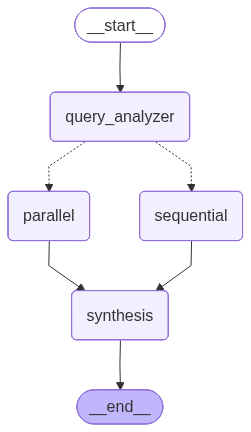

In [27]:
# Visualize the graph
try:
    from IPython.display import Image, display
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"Visualization not available: {e}")
    print("\nYou can view the graph structure using Mermaid:")
    print(app.get_graph().draw_mermaid())

## Part 12: Test the Workflow

Let's test our workflow with different types of queries!

### Test 1: Sequential Execution Query

This query requires finding information first, then using it to search for more specific information.

In [28]:
# Test 1: Sequential query
test_query_1 = "What AI products were launched by the company that acquired DeepMind in 2024?"

print(f"\n{'#'*80}")
print("TEST 1: SEQUENTIAL EXECUTION")
print(f"{'#'*80}")
print(f"Query: {test_query_1}")
print(f"{'#'*80}\n")

# Create initial state
initial_state_1 = {
    "query": test_query_1,
    "sub_queries": [],
    "execution_strategy": "",
    "num_sequential_steps": 2,
    "search_results": [],
    "synthesis": "",
    "final_answer": ""
}

# Run the workflow
result_1 = app.invoke(initial_state_1)

# Display final result
print(f"\n\n{'='*80}")
print("FINAL RESULT")
print(f"{'='*80}")
print(f"\nExecution Strategy: {result_1['execution_strategy']}")
print(f"Number of Steps: {result_1['num_sequential_steps']}")
print(f"\nFinal Answer:\n{result_1['final_answer']}")
print(f"\n{'='*80}")


################################################################################
TEST 1: SEQUENTIAL EXECUTION
################################################################################
Query: What AI products were launched by the company that acquired DeepMind in 2024?
################################################################################


QUERY ANALYZER NODE
Analyzing query: What AI products were launched by the company that acquired DeepMind in 2024?

Execution Strategy: SEQUENTIAL
Number of Sequential Steps: 2
Reasoning: The query requires identifying the company that acquired DeepMind first, which is a prerequisite to then querying for the AI products launched by that company in 2024. Therefore, it involves a sequential execution strategy.

Sub-queries generated:
  1. Which company acquired DeepMind?

Routing to: sequential execution node

SEQUENTIAL EXECUTION NODE
Executing 2 sequential steps...

--- Step 1/2 ---
Query: Which company acquired DeepMind?
Found 5 re

### Test 2: Parallel Execution Query

This query involves multiple independent pieces of information that can be searched simultaneously.

In [29]:
# Test 2: Parallel query
test_query_2 = "Summarize Tesla's Q4 2024 earnings, recent product launches, and leadership changes"

print(f"\n{'#'*80}")
print("TEST 2: PARALLEL EXECUTION")
print(f"{'#'*80}")
print(f"Query: {test_query_2}")
print(f"{'#'*80}\n")

# Create initial state
initial_state_2 = {
    "query": test_query_2,
    "sub_queries": [],
    "execution_strategy": "",
    "num_sequential_steps": 2,  # Not used for parallel, but required field
    "search_results": [],
    "synthesis": "",
    "final_answer": ""
}

# Run the workflow
result_2 = app.invoke(initial_state_2)

# Display final result
print(f"\n\n{'='*80}")
print("FINAL RESULT")
print(f"{'='*80}")
print(f"\nExecution Strategy: {result_2['execution_strategy']}")
print(f"\nFinal Answer:\n{result_2['final_answer']}")
print(f"\n{'='*80}")


################################################################################
TEST 2: PARALLEL EXECUTION
################################################################################
Query: Summarize Tesla's Q4 2024 earnings, recent product launches, and leadership changes
################################################################################


QUERY ANALYZER NODE
Analyzing query: Summarize Tesla's Q4 2024 earnings, recent product launches, and leadership changes


Exception in callback Task.__step()
handle: <Handle Task.__step()>
Traceback (most recent call last):
  File "/Users/sajal/.pyenv/versions/3.12.5/lib/python3.12/asyncio/events.py", line 88, in _run
    self._context.run(self._callback, *self._args)
RuntimeError: cannot enter context: <_contextvars.Context object at 0x10cc82d80> is already entered



Execution Strategy: PARALLEL
Reasoning: The sub-queries are independent of each other, allowing them to be executed simultaneously without relying on the results of one another.

Sub-queries generated:
  1. Tesla Q4 2024 earnings
  2. Tesla recent product launches
  3. Tesla leadership changes

Routing to: parallel execution node

PARALLEL EXECUTION NODE

Executing 3 queries in parallel...
  1. Tesla Q4 2024 earnings
  2. Tesla recent product launches
  3. Tesla leadership changes

All 3 queries completed in parallel!

SYNTHESIS NODE

Synthesizing 3 search result(s) into final answer...

Final answer generated!


FINAL RESULT

Execution Strategy: parallel

Final Answer:
In Q4 2024, Tesla reported earnings that fell short of Wall Street expectations, with adjusted earnings per share at $0.73, slightly below the anticipated $0.75. For the full year, Tesla's revenue increased by just 1% to $97.7 billion, indicating a slowdown in growth amid a challenging market environment. The company a

### Test 3: Multi-hop Sequential Query (3 steps)

This query demonstrates the enhanced capability to handle more than 2 sequential steps. It requires finding information progressively through multiple hops.

In [ ]:
# Test 3: Multi-hop sequential query (3 steps)
test_query_3 = "What products has the CEO of the company that makes iPhone announced in 2024?"

print(f"\n{'#'*80}")
print("TEST 3: MULTI-HOP SEQUENTIAL EXECUTION (3 STEPS)")
print(f"{'#'*80}")
print(f"Query: {test_query_3}")
print(f"{'#'*80}\n")

# Create initial state
initial_state_3 = {
    "query": test_query_3,
    "sub_queries": [],
    "execution_strategy": "",
    "num_sequential_steps": 2,  # Will be determined by query analyzer
    "search_results": [],
    "synthesis": "",
    "final_answer": ""
}

# Run the workflow
result_3 = app.invoke(initial_state_3)

# Display final result
print(f"\n\n{'='*80}")
print("FINAL RESULT")
print(f"{'='*80}")
print(f"\nExecution Strategy: {result_3['execution_strategy']}")
print(f"Number of Steps: {result_3['num_sequential_steps']}")
print(f"\nFinal Answer:\n{result_3['final_answer']}")
print(f"\n{'='*80}")


################################################################################
TEST 3: MULTI-HOP SEQUENTIAL EXECUTION (3 STEPS)
################################################################################
Query: What products has the CEO of the company that makes iPhone announced in 2024?
################################################################################


QUERY ANALYZER NODE
Analyzing query: What products has the CEO of the company that makes iPhone announced in 2024?

Execution Strategy: SEQUENTIAL
Number of Sequential Steps: 3
Reasoning: The query requires multiple steps where the first step identifies the company that makes the iPhone, which is essential to determine who the CEO is in the second step, and finally to find out what products that CEO has announced in 2024. Each step depends on the result of the previous one.

Sub-queries generated:
  1. Which company makes iPhone?

Routing to: sequential execution node

SEQUENTIAL EXECUTION NODE
Executing 3 sequen